# Задача 7. Нейронные сети


## Список заданий

- [x] Найти данные в виде изображений для задачи классификации. Например, можно взять данные [отсюда](http://ufldl.stanford.edu/housenumbers/).
- [x] Реализовать классы, необходимые для построения сети со следующими слоями
	- FullyConnectedLayer
	- ReluLayer
	- FullyConnectedLayer
- [x] Использовать CrossEntropyLoss и L2-регуляризацию.
- [x] Обучить модель на тренировочных данных, подбирать параметры (особенно learning rate) на валидационной и оценить качество на тестовой. Анализировать графики train/val loss, проверять на каждом шаге корректность вычисления градиентов с помощью разностной оценки.
- [x] * (**+2 балла**) Добавить Batch normalization.
- [x] * (**+2 балла**) В качестве оптимизатор использовать один из: Momentum, RMSprop.
- [x] * (**+1 балл**) Также реализовать оптимизатор Adam.

## Описание работы

В качестве данных будет использоваться датасет из изображений 32х32 Street View House Numbers (SVHN): https://www.kaggle.com/datasets/olgabelitskaya/svhn-preproccessed-fragments

## Работа

### Подготовка библиотек

In [1]:
import urllib
from pathlib import Path
import socket
import time
import zipfile
import numpy as np
from scipy.io import loadmat
import pandas as pd
from collections.abc import Iterable
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

### Подготовка данных


In [2]:
svhn_url = 'https://www.kaggle.com/api/v1/datasets/download/olgabelitskaya/svhn-preproccessed-fragments'
DATA_DIR = Path('../../data/svhn')
arch_filename = 'svhn.zip'
local_filename = Path(DATA_DIR / arch_filename)
DATA_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_TIMEOUT_SEC = 600

def download_file(
    url: str, path: Path, timeout_sec: int = DOWNLOAD_TIMEOUT_SEC
) -> None:
    if path.exists() and path.stat().st_size > 0:
        print(f"Файл уже существует: {path}")
        return

    tmp_path = path.with_suffix(path.suffix + '.tmp')
    print(f"Установка {url} -> {path}")
    previous_timeout = socket.getdefaulttimeout()
    socket.setdefaulttimeout(timeout_sec)
    try:
        started_at = time.perf_counter()
        with urllib.request.urlopen(url, timeout=timeout_sec) as response:
            with tmp_path.open('wb') as file:
                while True:
                    if time.perf_counter() - started_at > timeout_sec:
                        msg = f"Ошибка: timeout спустя {timeout_sec} секунд"
                        raise TimeoutError(msg)
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    file.write(chunk)
        tmp_path.replace(path)
    finally:
        socket.setdefaulttimeout(previous_timeout)
        if tmp_path.exists():
            tmp_path.unlink()
        print('Успешно установлено')

download_file(svhn_url, local_filename)

Файл уже существует: ../../data/svhn/svhn.zip


In [3]:
CONTENTS_DIR = DATA_DIR / 'contents'
contents_ok = CONTENTS_DIR.exists() and CONTENTS_DIR.stat().st_size > 0

if not contents_ok:
    with zipfile.ZipFile(local_filename, 'r') as zip_ref:
        zip_ref.extractall(CONTENTS_DIR)
    print('Архив распакован в ', CONTENTS_DIR)
else:
    print('Архив уже распакован в ', CONTENTS_DIR)

Архив уже распакован в  ../../data/svhn/contents


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def load_images_labels(name: str) -> tuple[np.ndarray, np.ndarray] | None:
    if name != "train" and name != "test":
        return None
    img_path = CONTENTS_DIR / f"{name}_images.csv"
    lbl_path = CONTENTS_DIR / f"{name}_labels.csv"

    img_df = pd.read_csv(img_path)
    lbl_df = pd.read_csv(lbl_path)

    return img_df.values, lbl_df.values

X_train_full, y_train_full = load_images_labels("train")
filenames = y_train_full[:, 0]
y_train_full = y_train_full[:, 1:].astype(np.float32)
X_train_full = X_train_full[:, 1:].astype(np.float32)

X_test_full, y_test_full = load_images_labels("test")
y_test_full = y_test_full[:, 1:].astype(np.float32)
X_test_full = X_test_full[:, 1:].astype(np.float32)

print("Train:", X_train_full.shape, X_train_full.dtype,
      X_train_full.min(), X_train_full.max())
print("Test: ", X_test_full.shape,  X_test_full.dtype)
print("Train y:", y_train_full.shape)
print("Test  y:", y_test_full.shape)

Train: (13000, 1024) float32 0.003964706 1.0
Test:  (6000, 1024) float32
Train y: (13000, 5)
Test  y: (6000, 5)


#### Данные уже имеют нужную размерность и масштабированы в [0, 1]. Посмотрим, как они выглядят.

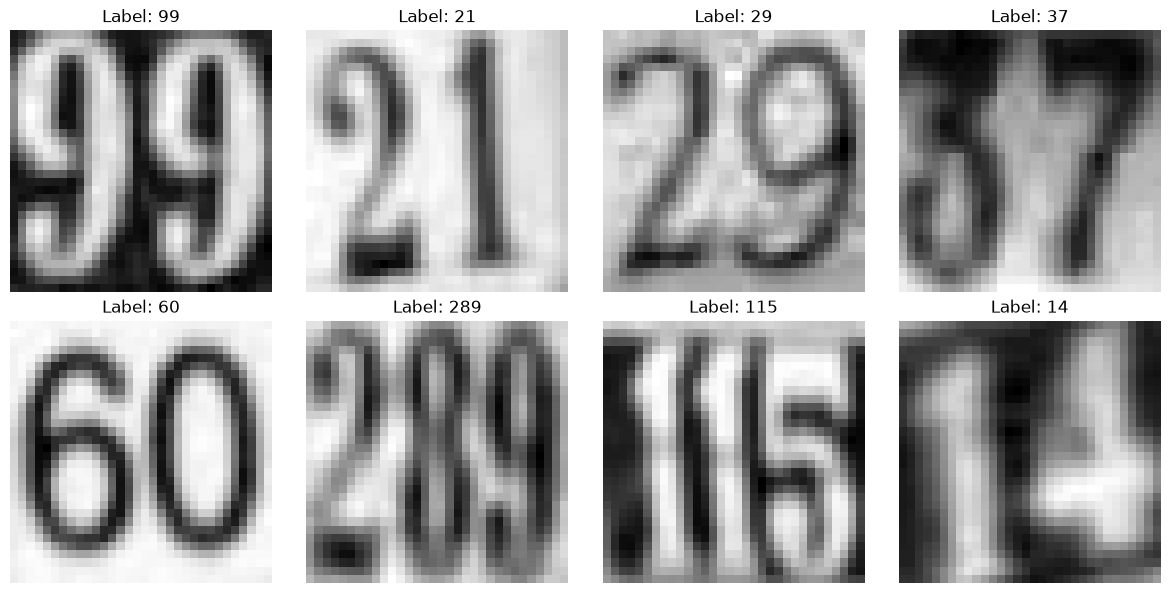

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.ravel()

random_indices = np.random.choice(len(X_train_full), size=8, replace=False)

for i, idx in enumerate(random_indices):
    img_matrix = X_train_full[idx].reshape(32, 32)
    raw_label = y_train_full[idx]

    active_digits = [int(digit) for digit in raw_label if digit < 10]
    label_text = "".join(map(str, active_digits))

    axes[i].imshow(img_matrix, cmap="gray")
    axes[i].set_title(f"Label: {label_text}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


#### Выделим часть данных

In [6]:
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 10000, 200, 400

X_train_small, _, y_train_small, _ = train_test_split(
    X_train_full,
    y_train_full,
    train_size=TRAIN_SIZE + VAL_SIZE,
    random_state=RANDOM_STATE,
)
X_train_img, X_val_img, y_train, y_val = train_test_split(
    X_train_small,
    y_train_small,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
)
X_test_img, _, y_test, _ = train_test_split(
    X_test_full,
    y_test_full,
    train_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

train_mean = X_train_img.mean(axis=0, keepdims=True)
train_std  = X_train_img.std(axis=0, keepdims=True) + 1e-7

X_train = (X_train_img - train_mean) / train_std
X_val = (X_val_img - train_mean) / train_std
X_test = (X_test_img - train_mean) / train_std

print("shapes:", X_train.shape, X_val.shape, X_test.shape,
      y_train.shape, y_val.shape, y_test.shape)

shapes: (10000, 1024) (200, 1024) (400, 1024) (10000, 5) (200, 5) (400, 5)


### Реализация классов

#### Слои

In [7]:
class FullyConnectedLayer:
    def __init__(self, in_features: int, out_features: int, weight_scale: float = 1e-2) -> None:
        self.W = rng.normal(0.0, weight_scale, size=(in_features, out_features))
        self.b = np.zeros(out_features)

        self.dW = None
        self.db = None
        self.x = None

    def forward(self, x: np.ndarray, training: bool = True) -> np.ndarray:
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout: np.ndarray) -> np.ndarray:
        x = self.x if self.x.ndim == 2 else self.x[None, :]
        dout = dout if dout.ndim == 2 else dout[None, :]

        self.dW = x.T @ dout
        self.db = np.sum(dout, axis=0)

        dx = dout @ self.W.T
        return dx if self.x.ndim == 2 else dx[0]

    def params(self) -> dict[str, np.ndarray]:
        return {"W": self.W, "b": self.b}

    def grads(self) -> dict[str, np.ndarray]:
        return {"W": self.dW, "b": self.db}

class ReluLayer:
    def __init__(self) -> None:
        self.mask = None

    def forward(self, x: np.ndarray, training: bool = True) -> np.ndarray:
        self.mask = x > 0
        return np.maximum(x, 0)

    def backward(self, dout: np.ndarray) -> np.ndarray:
        return dout * self.mask

    def params(self) -> dict[str, np.ndarray]:
        return {}

    def grads(self) -> dict[str, np.ndarray]:
        return {}

class BatchNormLayer:
    def __init__(self, num_features, eps=1e-5, momentum=0.9):
        self.eps = eps
        self.momentum = momentum
        self.gamma = np.ones(num_features)
        self.beta = np.zeros(num_features)

        self.running_mean = np.zeros(num_features)
        self.running_var = np.ones(num_features)

        self.dgamma = None
        self.dbeta = None

        # кэш для backward
        self.x_norm = None
        self.std = None

    def forward(self, x, training=True, update_running=True):
        if training:
            mean = x.mean(axis=0)
            var = x.var(axis=0)
            self.std = np.sqrt(var + self.eps)
            self.x_norm = (x - mean) / self.std

            if update_running:
                self.running_mean = (
                    self.momentum * self.running_mean
                    + (1.0 - self.momentum) * mean
                )
                self.running_var = (
                    self.momentum * self.running_var
                    + (1.0 - self.momentum) * var
                )
        else:
            self.x_norm = (x - self.running_mean) / np.sqrt(self.running_var + self.eps)

        return self.gamma * self.x_norm + self.beta

    def backward(self, dout):
        self.dgamma = np.sum(dout * self.x_norm, axis=0)
        self.dbeta = np.sum(dout, axis=0)

        dx_hat = dout * self.gamma
        dx = (1.0 / self.std) * (
            dx_hat
            - dx_hat.mean(axis=0)
            - self.x_norm * (dx_hat * self.x_norm).mean(axis=0)
        )
        return dx

    def params(self):
        return {"gamma": self.gamma, "beta": self.beta}

    def grads(self):
        return {"gamma": self.dgamma, "beta": self.dbeta}

#### CrossEntropyLoss

In [8]:
class CrossEntropyLoss:
    def __init__(self):
        self.probs = None
        self.targets = None
        self.num_positions = None
        self.num_classes = None

    def forward(self, logits, targets):
        # logits: (N, P, C); targets: (N, P), значения в [0, C)
        assert logits.ndim == 3, f"logits должны быть (N, P, C), получено {logits.shape}"

        targets = np.asarray(targets).astype(np.int64)   # ← ключевое
        assert targets.ndim == 2, f"targets должны быть (N, P), получено {targets.shape}"

        self.num_positions = logits.shape[1]
        self.num_classes = logits.shape[2]
        self.targets = targets

        # стабильный softmax по последней оси
        z = logits - logits.max(axis=-1, keepdims=True)
        exp_z = np.exp(z)
        self.probs = exp_z / exp_z.sum(axis=-1, keepdims=True)   # (N, P, C)

        N = logits.shape[0]
        rows = np.arange(N)[:, None]                  # (N, 1)
        cols = np.arange(self.num_positions)[None, :] # (1, P)

        # тройная индексация: для каждого (n, p) берём вероятность класса targets[n, p]
        correct = self.probs[rows, cols, targets]     # (N, P)

        return -np.log(np.clip(correct, 1e-12, 1.0)).mean()

    def backward(self):
        N = self.probs.shape[0]
        dlogits = self.probs.copy()
        rows = np.arange(N)[:, None]
        cols = np.arange(self.num_positions)[None, :]
        dlogits[rows, cols, self.targets] -= 1.0
        dlogits /= N
        dlogits /= self.num_positions
        return dlogits

#### Neural Network

In [9]:
class NeuralNetwork:
    def __init__(self, layers: list[object]) -> None:
        self.layers = layers
        self.training = True

    def forward(
        self,
        x: np.ndarray,
        training: bool = True,
        update_running: bool = True,
    ) -> np.ndarray:
        output = x
        for layer in self.layers:
            if isinstance(layer, BatchNormLayer):
                output = layer.forward(
                    output, training=self.training, update_running=update_running
                )
            else:
                output = layer.forward(output)
        return output

    def backward(self, grad: np.ndarray) -> np.ndarray:
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def parameters(self) -> Iterable[tuple[str, np.ndarray, np.ndarray]]:
        for layer_idx, layer in enumerate(self.layers):
            params = layer.params()
            grads = layer.grads()
            for name, param in params.items():
                yield f"layer_{layer_idx}.{name}", param, grads[name]


def l2_penalty_and_grads(model: NeuralNetwork, l2_reg: float) -> float:
    penalty = 0.0
    for name, param, grad in model.parameters():
        if name.endswith(".W"):
            penalty += 0.5 * l2_reg * float(np.sum(param * param))
            grad += l2_reg * param
    return penalty


def make_model(
    input_dim: int,
    hidden_dim: int,
    num_classes: int,
    use_batch_norm: bool,
) -> NeuralNetwork:
    weight_scale = np.sqrt(2.0 / input_dim)
    layers: list[object] = [FullyConnectedLayer(input_dim, hidden_dim, weight_scale)]
    if use_batch_norm:
        layers.append(BatchNormLayer(hidden_dim))
    layers.extend(
        [
            ReluLayer(),
            FullyConnectedLayer(hidden_dim, num_classes, np.sqrt(2.0 / hidden_dim)),
        ]
    )
    return NeuralNetwork(layers)

#### Оптимизаторы

In [10]:
class Optimizer:
    def step(self, model: NeuralNetwork) -> None:
        raise NotImplementedError

class MomentumOptimizer(Optimizer):
    def __init__(self, learning_rate: float = 1e-2, momentum: float = 0.9) -> None:
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.velocity: dict[str, np.ndarray] = {}

    def step(self, model: NeuralNetwork) -> None:
        for name, param, grad in  model.parameters():
            velocity = self.velocity.setdefault(name, np.zeros_like(param))
            velocity *= self.momentum
            velocity -= self.learning_rate * grad
            param += velocity

class AdamOptimizer(Optimizer):
    def __init__(
        self,
        learning_rate: float = 3e-4,
        beta1: float = 0.9,
        beta2: float = 0.999,
        eps: float = 1e-8,
    ) -> None:
        self.learning_rate = learning_rate
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m: dict[str, np.ndarray] = {}
        self.v: dict[str, np.ndarray] = {}

    def step(self, model: NeuralNetwork) -> None:
        self.t += 1
        bc1 = 1.0 - self.beta1 ** self.t
        bc2 = 1.0 - self.beta2 ** self.t
        for name, param, grad in model.parameters():
            m = self.m.setdefault(name, np.zeros_like(param))
            v = self.v.setdefault(name, np.zeros_like(param))
            m *= self.beta1
            m += (1 - self.beta1) * grad
            v *= self.beta2
            v += (1 - self.beta2) * grad * grad
            m_hat = m / bc1
            v_hat = v / bc2
            param -= self.learning_rate * m_hat / (np.sqrt(v_hat) + self.eps)

def make_optimizer(name: str, learning_rate: float) -> Optimizer:
    if name == "momentum":
        return MomentumOptimizer(learning_rate=learning_rate)
    if name == "adam":
        return AdamOptimizer(learning_rate=learning_rate)
    raise ValueError(f"Unknown optimizer: {name}")

#### Проверка вычисления градиентов

In [11]:
def calculate_loss(
    model: NeuralNetwork,
    x: np.ndarray,
    y: np.ndarray,
    l2_reg: float,
    training: bool = True,
    update_running: bool = True,
) -> float:
    loss_fn = CrossEntropyLoss()
    logits_flat = model.forward(x, training=training, update_running=update_running)
    logits = logits_flat.reshape(x.shape[0], 5, 11)           # ← добавлено
    data_loss = loss_fn.forward(logits, y)
    penalty = 0.0
    for name, param, _ in model.parameters():
        if name.endswith(".W"):
            penalty += 0.5 * l2_reg * float(np.sum(param * param))
    return data_loss + penalty


def calculate_loss_and_grads(
    model: NeuralNetwork,
    x: np.ndarray,
    y: np.ndarray,
    l2_reg,
    update_running: bool = True,
) -> float:
    loss_fn = CrossEntropyLoss()
    logits_flat = model.forward(x, training=True, update_running=update_running)
    logits = logits_flat.reshape(x.shape[0], 5, 11)          # ← добавлено
    data_loss = loss_fn.forward(logits, y)
    grad_logits = loss_fn.backward()                          # (N, 5, 11)
    model.backward(grad_logits.reshape(x.shape[0], -1))       # ← reshape обратно
    return data_loss + l2_penalty_and_grads(model, l2_reg)


def sample_indices(shape: tuple[int, ...], checks: int) -> list[tuple[int, ...]]:
    n = int(np.prod(shape))
    count = min(checks, n)
    flat_indices = rng.choice(n, size=count, replace=False)
    return [np.unravel_index(index, shape) for index in flat_indices]


def check_gradient(
    model: NeuralNetwork,
    x: np.ndarray,
    y: np.ndarray,
    l2_reg: float,
    eps: float = 1e-5,
    checks_per_param: int = 3,
) -> pd.DataFrame:
    loss = calculate_loss_and_grads(model, x, y, l2_reg, False)
    rows = []

    for name, param, grad in model.parameters():
        max_relative_error = 0.0
        indices = sample_indices(param.shape, checks_per_param)
        for index in indices:
            old_value = param[index]
            param[index] = old_value + eps
            loss_plus = calculate_loss(model, x, y, l2_reg, False)
            param[index] = old_value - eps
            loss_minus = calculate_loss(model, x, y, l2_reg, False)
            param[index] = old_value

            numerical = (loss_plus - loss_minus) / (2 * eps)
            analytical = grad[index]
            denom = max(1e-8, abs(numerical) + abs(analytical))
            relative_error = abs(numerical - analytical) / denom
            max_relative_error = max(max_relative_error, float(relative_error))

        rows.append({"parameter": name, "loss": loss, "max_relative_error": max_relative_error})

    return pd.DataFrame(rows)

#### Обучение с подбором гиперпараметров

In [12]:
def iterate_minibatches(
    x: np.ndarray,
    y: np.ndarray,
    batch_size: int,
    shuffle: bool = True,
) -> Iterable[tuple[np.ndarray, np.ndarray]]:
    indices = np.arange(x.shape[0])
    if shuffle:
        rng.shuffle(indices)
    for start in range(0, x.shape[0], batch_size):
        batch_indices = indices[start : start + batch_size]
        yield x[batch_indices], y[batch_indices]


def predict(
    model: NeuralNetwork, x: np.ndarray, batch_size: int = 512
) -> np.ndarray:
    predictions = []
    dummy_y = np.zeros(x.shape[0], dtype=int)
    for x_batch, _ in iterate_minibatches(x, dummy_y, batch_size, shuffle=False):
        logits = model.forward(x_batch, training=False)
        logits = logits.reshape(x_batch.shape[0], 5, 11)     # ← добавлено
        predictions.append(np.argmax(logits, axis=-1))        # (N, 5)
    return np.concatenate(predictions, axis=0)


def evaluate_model(
    model: NeuralNetwork,
    x: np.ndarray,
    y: np.ndarray,
    l2_reg: float,
) -> dict[str, float]:
    loss = calculate_loss(model, x, y, l2_reg, training=False)
    y_pred = predict(model, x)                       # (N, 5)
    per_position = (y == y_pred).mean(axis=0)        # (5,)
    return {
        "loss": loss,
        "accuracy": float(per_position.mean()),      # среднее по позициям
        "pos_accuracy": per_position,
    }


def train_model(
    config: dict[str, object],
    x_train: np.ndarray,
    y_train: np.ndarray,
    x_val: np.ndarray,
    y_val: np.ndarray,
) -> tuple[NeuralNetwork, pd.DataFrame, pd.DataFrame]:
    model = make_model(
        input_dim=x_train.shape[1],
        hidden_dim=int(config["hidden_dim"]),
        num_classes=5*11,
        use_batch_norm=bool(config["use_batch_norm"]),
    )
    optimizer = make_optimizer(
        name=str(config["optimizer"]),
        learning_rate=float(config["learning_rate"]),
    )
    batch_size = int(config["batch_size"])
    epochs = int(config["epochs"])
    l2_reg = float(config["l2_reg"])
    gradient_check_steps = int(config.get("gradient_check_steps", 0))

    history = []
    gradient_rows = []
    global_step = 0
    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        batch_losses = []
        for x_batch, y_batch in iterate_minibatches(x_train, y_train, batch_size):
            global_step += 1
            loss = calculate_loss_and_grads(model, x_batch, y_batch, l2_reg)

            if global_step <= gradient_check_steps:
                check_table = check_gradient(
                    model,
                    x_batch[:8],
                    y_batch[:8],
                    l2_reg,
                    checks_per_param=2,
                )
                check_table["step"] = global_step
                gradient_rows.append(check_table)
                calculate_loss_and_grads(model, x_batch, y_batch, l2_reg)

            optimizer.step(model)
            batch_losses.append(loss)

        train_metrics = evaluate_model(model, x_train, y_train, l2_reg)
        val_metrics = evaluate_model(model, x_val, y_val, l2_reg)
        history.append(
            {
                "epoch": epoch,
                "train_batch_loss": float(np.mean(batch_losses)),
                "train_loss": train_metrics["loss"],
                "train_accuracy": train_metrics["accuracy"],
                "val_loss": val_metrics["loss"],
                "val_accuracy": val_metrics["accuracy"],
                "elapsed_sec": time.perf_counter() - start_time,
            }
        )

    gradient_table = (
        pd.concat(gradient_rows, ignore_index=True) if gradient_rows else pd.DataFrame()
    )
    return model, pd.DataFrame(history), gradient_table

In [13]:
base_config = {
    "hidden_dim": 256,
    "batch_size": 256,
    "epochs": 25,
    "l2_reg": 3e-3,
    "use_batch_norm": True,
    "gradient_check_steps": 1,
}

experiment_configs = [
    {**base_config, "optimizer": "momentum", "learning_rate": 3e-2},
    {**base_config, "optimizer": "momentum", "learning_rate": 1e-2},
    {**base_config, "optimizer": "adam", "learning_rate": 1e-3},
    {
        **base_config,
        "optimizer": "adam",
        "learning_rate": 1e-3,
        "use_batch_norm": False,
    },
] 


experiment_rows = []
histories = []
gradient_checks = []
trained_models = []

for experiment_id, config in enumerate(experiment_configs, start=1):
    print(f"Experiment {experiment_id}: {config}")
    model, history, check_table = train_model(config, X_train, y_train, X_val, y_val)
    history["experiment_id"] = experiment_id
    history["optimizer"] = config["optimizer"]
    history["learning_rate"] = config["learning_rate"]
    history["use_batch_norm"] = config["use_batch_norm"]
    histories.append(history)

    if not check_table.empty:
        check_table["experiment_id"] = experiment_id
        gradient_checks.append(check_table)

    best_epoch = history.sort_values("val_accuracy", ascending=False).iloc[0]
    experiment_rows.append(
        {
            "experiment_id": experiment_id,
            "optimizer": config["optimizer"],
            "learning_rate": config["learning_rate"],
            "use_batch_norm": config["use_batch_norm"],
            "best_epoch": int(best_epoch["epoch"]),
            "best_val_loss": best_epoch["val_loss"],
            "best_val_accuracy": best_epoch["val_accuracy"],
            "final_train_accuracy": history.iloc[-1]["train_accuracy"],
            "elapsed_sec": history.iloc[-1]["elapsed_sec"],
        }
    )
    trained_models.append(model)

all_history = pd.concat(histories, ignore_index=True)
gradient_check_results = pd.concat(gradient_checks, ignore_index=True)
experiment_results = pd.DataFrame(experiment_rows).sort_values(
    "best_val_accuracy",
    ascending=False,
)
display(experiment_results)

Experiment 1: {'hidden_dim': 256, 'batch_size': 256, 'epochs': 25, 'l2_reg': 0.003, 'use_batch_norm': True, 'gradient_check_steps': 1, 'optimizer': 'momentum', 'learning_rate': 0.03}
Experiment 2: {'hidden_dim': 256, 'batch_size': 256, 'epochs': 25, 'l2_reg': 0.003, 'use_batch_norm': True, 'gradient_check_steps': 1, 'optimizer': 'momentum', 'learning_rate': 0.01}
Experiment 3: {'hidden_dim': 256, 'batch_size': 256, 'epochs': 25, 'l2_reg': 0.003, 'use_batch_norm': True, 'gradient_check_steps': 1, 'optimizer': 'adam', 'learning_rate': 0.001}
Experiment 4: {'hidden_dim': 256, 'batch_size': 256, 'epochs': 25, 'l2_reg': 0.003, 'use_batch_norm': False, 'gradient_check_steps': 1, 'optimizer': 'adam', 'learning_rate': 0.001}


,experiment_id,optimizer,learning_rate,use_batch_norm,best_epoch,best_val_loss,best_val_accuracy,final_train_accuracy,elapsed_sec
3,4,adam,0.001,False,25,0.965545,0.780,0.84090,24.539103
0,1,momentum,0.030,True,24,1.060123,0.764,0.81814,22.293476
2,3,adam,0.001,True,20,0.972462,0.753,0.81162,28.434277
1,2,momentum,0.010,True,22,1.500542,0.739,0.79954,28.097618


#### Оценка на тестовых данных

Лучшая конфигурация: experiment_id=4


,experiment_id,optimizer,learning_rate,use_batch_norm,best_epoch,best_val_loss,best_val_accuracy,final_train_accuracy,elapsed_sec
3,4,adam,0.001,False,25,0.965545,0.78,0.8409,24.539103


,split,loss,accuracy,pos_accuracy
0,train,0.775220,0.8409,"[0.9998, 0.9742, 0.8439, 0.7011, 0.6855]"
1,validation,0.965545,0.7800,"[1.0, 0.935, 0.81, 0.625, 0.53]"
2,test,0.885054,0.8080,"[1.0, 0.99, 0.87, 0.635, 0.545]"



===== Позиция 0 =====
              precision    recall  f1-score   support

        10.0      1.000     1.000     1.000       400

    accuracy                          1.000       400
   macro avg      1.000     1.000     1.000       400
weighted avg      1.000     1.000     1.000       400


===== Позиция 1 =====
              precision    recall  f1-score   support

         1.0      1.000     0.200     0.333         5
         2.0      1.000     1.000     1.000         1
        10.0      0.990     1.000     0.995       394

    accuracy                          0.990       400
   macro avg      0.997     0.733     0.776       400
weighted avg      0.990     0.990     0.987       400


===== Позиция 2 =====
              precision    recall  f1-score   support

         0.0      0.000     0.000     0.000         2
         1.0      0.553     0.553     0.553        38
         2.0      0.429     0.250     0.316        12
         3.0      0.625     0.833     0.714         6
      

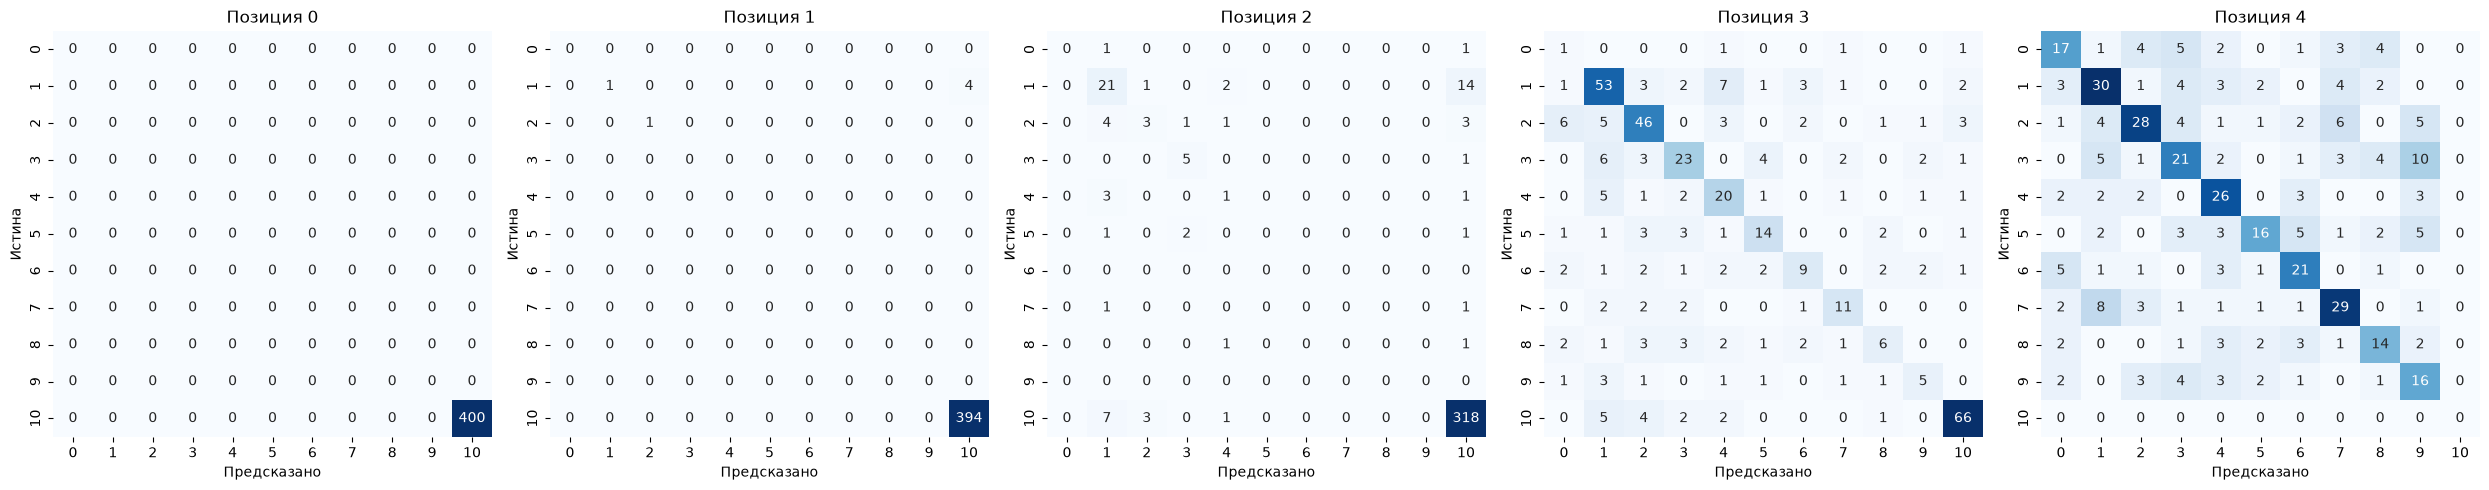

In [14]:
best_experiment = experiment_results.iloc[0]
best_experiment_id = int(best_experiment["experiment_id"])
best_model = trained_models[best_experiment_id - 1]

train_eval = evaluate_model(best_model, X_train, y_train, float(base_config["l2_reg"]))
val_eval = evaluate_model(best_model, X_val, y_val, float(base_config["l2_reg"]))
test_eval = evaluate_model(best_model, X_test, y_test, float(base_config["l2_reg"]))

evaluation_table = pd.DataFrame(
    [
        {"split": "train", **train_eval},
        {"split": "validation", **val_eval},
        {"split": "test", **test_eval},
    ]
)
print(f"Лучшая конфигурация: experiment_id={best_experiment_id}")
display(best_experiment.to_frame().T)
display(evaluation_table)

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
y_test_pred = predict(best_model, X_test)       # (N, 5)
for pos in range(5):
    print(f"\n===== Позиция {pos} =====")
    print(classification_report(
        y_test[:, pos], y_test_pred[:, pos],
        digits=3, zero_division=0,
    ))
    y_test_pred = predict(best_model, X_test)
    cm = confusion_matrix(y_test[:, pos], y_test_pred[:, pos], labels=range(11))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[pos],
                cbar=False)
    axes[pos].set_title(f"Позиция {pos}")
    axes[pos].set_xlabel("Предсказано")
    axes[pos].set_ylabel("Истина")
plt.tight_layout()
plt.show()

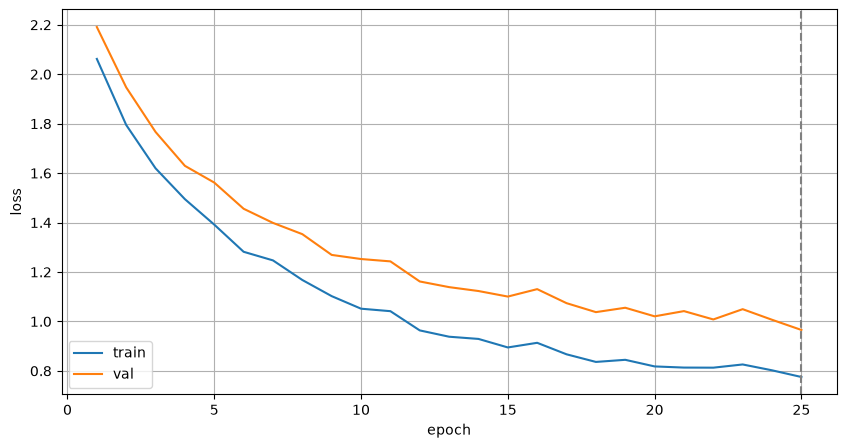

In [15]:
hist = all_history[all_history["experiment_id"] == 4]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist["epoch"], hist["train_loss"], label="train")
ax.plot(hist["epoch"], hist["val_loss"],   label="val")
ax.axvline(hist.iloc[hist["val_loss"].argmin()]["epoch"], ls="--", c="gray")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.legend(); ax.grid(True); plt.show()

Обе кривые монотонно убывают и не расходятся, разрыв составляет около 0.2 к 15-й эпохе и дальше не растёт. После 25-й эпохи val loss уходит на плато, поэтому эта эпоха выбрана в качестве финальной.

## Выводы

1. Использованы изображения SVHN для классификации цифр 0--9.
2. Реализована архитектура FullyConnectedLayer -> ReluLayer -> FullyConnectedLayer, реализованы данные классы.
3. Добавлен слой BatchNormLayer.
4. Использованы CrossEntropyLoss и L2-регуляризация.
5. Использованы оптимизаторы Momentum и Adam.
6. Были подобраны оптимальные гиперпараметры для модели, после чего она была обучена на тренировочных данных.